# Comptage de mots : comparaison de quatre méthodes

1. Python séquentiel ;
2. pseudo-MapReduce Python (`map`, `shuffle`, `reduce`) par blocs ;
3. Hadoop MapReduce sur HDFS/YARN ;
4. Spark en mode local.

Après la validation des petits fichiers, cette version prépare les tailles suivantes : **10 000, 100 000, 1 million, 5 millions, 10 millions, 20 millions et 50 millions de lignes**. Les quatre méthodes utilisent le même fichier et doivent produire exactement les mêmes comptages à chaque taille.

Exécuter les cellules dans l'ordre. Le notebook a été préparé sans lancer cette grande série. Les résultats sont enregistrés progressivement dans `donnees_comptage/resultats_reels.csv` ; les résultats précédents sont archivés au démarrage du benchmark.


In [1]:
import importlib.util

bibliotheques = ['pandas', 'matplotlib', 'pyspark']
manquantes = [nom for nom in bibliotheques if importlib.util.find_spec(nom) is None]
if manquantes:
    get_ipython().run_line_magic('pip', 'install -q ' + ' '.join(manquantes))
print('Bibliothèques disponibles : pandas, matplotlib, pyspark.')


Bibliothèques disponibles : pandas, matplotlib, pyspark.


In [2]:
from collections import Counter, defaultdict
from statistics import median
from itertools import islice
from datetime import datetime
import threading
import os
from pathlib import Path
import shutil
import subprocess
import tempfile
import re
import sys
import uuid
import time

import pandas as pd
import matplotlib.pyplot as plt

# Connexion automatique à l'installation Hadoop locale.
HADOOP_HOME = Path.home() / 'hadoop'
if HADOOP_HOME.exists():
    os.environ['HADOOP_HOME'] = str(HADOOP_HOME)
    os.environ['HADOOP_CONF_DIR'] = str(HADOOP_HOME / 'etc/hadoop')
    os.environ['PATH'] = str(HADOOP_HOME / 'bin') + os.pathsep + str(HADOOP_HOME / 'sbin') + os.pathsep + os.environ.get('PATH', '')

DOSSIER = Path('donnees_comptage')
DOSSIER.mkdir(exist_ok=True)
EXECUTION_ID = datetime.now().strftime('%Y%m%d_%H%M%S') + '_' + uuid.uuid4().hex[:8]
DOSSIER_TEXTES = DOSSIER / 'grands_tests' / EXECUTION_ID
DOSSIER_TEXTES.mkdir(parents=True, exist_ok=True)
DOSSIER_LOGS = DOSSIER / 'logs_hadoop'
DOSSIER_LOGS.mkdir(exist_ok=True)

# Paramètres à modifier pour une prochaine série.
N_VALIDATION = 1_000
N_BASE = 10_000
MULTIPLICATEURS = [1, 10, 100, 500, 1_000, 2_000, 5_000]
TAILLE_BLOC = 100_000
REPETITIONS = 1  # Une exécution réelle par méthode et par taille.
INTERVALLE_PROGRESSION_S = 5
TIMEOUT_HADOOP_S = 1_800
TIMEOUT_TRANSFERT_S = 600
CONSERVER_FICHIERS = False  # Nettoyer seulement les fichiers créés par cette exécution.
MOTS = ['chat', 'chien', 'arbre', 'fleur', 'maison', 'soleil',
        'montagne', 'livre', 'ciel', 'mer', 'lune', 'route']


## 1. Génération et suivi des fichiers

Une ligne contient un mot. Les sept tailles vont d'environ **60 ko à 300 Mo** avec la liste `MOTS` actuelle. La génération affiche son pourcentage réel et le temps écoulé.

Les textes sont créés dans un dossier propre à chaque exécution. Par défaut, chaque gros texte est supprimé après les quatre mesures réussies ; les CSV, les journaux et les graphiques restent disponibles. `CONSERVER_FICHIERS = True` permet de conserver les textes. Une vérification d'espace tient compte des copies locales/HDFS et garde une marge au-dessus du seuil disque de YARN.


In [3]:
def generer_fichier_base(n=N_BASE, chemin=None):
    """Crée n lignes, une ligne = un mot, sans charger tout le fichier en mémoire."""
    chemin = DOSSIER_TEXTES / 'mots_N.txt' if chemin is None else Path(chemin)
    with chemin.open('w', encoding='utf-8') as fichier:
        for i in range(n):
            fichier.write(MOTS[i % len(MOTS)] + '\n')
    return chemin

def verifier_espace(taille_octets):
    espace = shutil.disk_usage(DOSSIER_TEXTES)
    # Un texte local, une copie temporaire et une copie HDFS sur ce nœud local.
    copies = 3 * taille_octets
    reserve = max(int(espace.total * 0.10) + 256 * 1024**2, 2 * 1024**3)
    if espace.free < copies + reserve:
        manque = (copies + reserve - espace.free) / 1e9
        raise RuntimeError(f'Espace insuffisant pour cette taille : libérer environ {manque:.2f} Go '
                           'ou réduire MULTIPLICATEURS. La génération a été arrêtée avant écriture.')

def generer_fichier(n=N_BASE, m=1):
    """Duplique la base par blocs et affiche les octets réellement écrits."""
    if n <= 0 or m <= 0:
        raise ValueError('n et m doivent être strictement positifs.')
    base = generer_fichier_base(n)
    sortie = DOSSIER_TEXTES / f'mots_{n}_x_{m}.txt'
    total_octets = base.stat().st_size * m
    verifier_espace(total_octets)
    debut = derniere_info = time.perf_counter()
    ecrits = 0
    print(f'Génération : {n*m:,} lignes ; {total_octets/1e6:.2f} Mo prévus.', flush=True)
    with base.open('rb') as source, sortie.open('wb') as destination:
        for _ in range(m):
            source.seek(0)
            while bloc := source.read(1024 * 1024):
                destination.write(bloc)
                ecrits += len(bloc)
                maintenant = time.perf_counter()
                if maintenant - derniere_info >= INTERVALLE_PROGRESSION_S:
                    print(f'    Génération {100*ecrits/total_octets:.1f} % — '
                          f'{ecrits/1e6:.2f}/{total_octets/1e6:.2f} Mo — '
                          f'{maintenant-debut:.1f} s', flush=True)
                    derniere_info = maintenant
    assert sortie.stat().st_size == total_octets
    print(f'    Génération 100 % — {time.perf_counter()-debut:.1f} s.', flush=True)
    return sortie

# Le contrôle initial reste petit, même pour une grande série.
fichier_exemple = generer_fichier(n=N_VALIDATION, m=1)
print('Fichier de validation :', fichier_exemple)


Génération : 1,000 lignes ; 0.01 Mo prévus.
    Génération 100 % — 0.0 s.
Fichier de validation : donnees_comptage/grands_tests/20261013_155314_cd37268b/mots_1000_x_1.txt


## 2. Les quatre méthodes

### Version 1 : Python simple

Comptage séquentiel ligne par ligne, pour garder une consommation de mémoire limitée sur les grandes tailles.


In [4]:
def compter_simple(chemin):
    """Méthode 1 : lecture séquentielle et dictionnaire."""
    compteur = {}
    with open(chemin, encoding='utf-8') as fichier:
        for ligne in fichier:
            for mot in ligne.split():
                compteur[mot] = compteur.get(mot, 0) + 1
    return compteur


### Version 2 : Pseudo-MapReduce Python

Les étapes `Map`, `Shuffle` et `Reduce` sont exécutées sur des blocs de **100 000 lignes**, puis les comptages partiels sont additionnés. Les listes intermédiaires restent limitées à un bloc.


In [5]:
def mapper(ligne):
    return [(mot, 1) for mot in ligne.split()]

def compter_pseudo_mapreduce(chemin, taille_bloc=TAILLE_BLOC):
    """Méthode 2 : Map/Shuffle/Reduce par blocs, puis fusion des comptes."""
    if taille_bloc <= 0:
        raise ValueError('taille_bloc doit être strictement positif.')
    resultat_final = Counter()

    def reduire_bloc(lignes):
        mapped = [paire for ligne in lignes for paire in mapper(ligne)]
        groupes = defaultdict(list)
        for mot, valeur in mapped:
            groupes[mot].append(valeur)
        return {mot: sum(valeurs) for mot, valeurs in groupes.items()}

    with open(chemin, encoding='utf-8') as fichier:
        while bloc := list(islice(fichier, taille_bloc)):
            resultat_final.update(reduire_bloc(bloc))
    return dict(resultat_final)


### Version 3 : Hadoop MapReduce

Le programme WordCount de Hadoop est exécuté sur HDFS/YARN. Chaque appel utilise un dossier HDFS unique et conserve son journal dans `donnees_comptage/logs_hadoop`. Un échec arrête la validation : aucune méthode n'est ignorée silencieusement.


In [6]:
def compter_hadoop(chemin):
    """Méthode 3 : véritable job Hadoop WordCount sur HDFS/YARN."""
    if any(shutil.which(nom) is None for nom in ('hadoop', 'hdfs', 'yarn')):
        raise RuntimeError('Hadoop, hdfs et yarn doivent être disponibles.')
    chemin = Path(chemin).resolve(strict=True)
    jars = sorted((HADOOP_HOME / 'share/hadoop/mapreduce').glob('hadoop-mapreduce-examples-*.jar'))
    if not jars:
        raise RuntimeError('JAR hadoop-mapreduce-examples introuvable.')
    identifiant = uuid.uuid4().hex
    dossier_hdfs = f'/tmp/comptage_benchmark_{identifiant}'
    entree, sortie = f'{dossier_hdfs}/input', f'{dossier_hdfs}/output'
    journal = DOSSIER_LOGS / f'wordcount_{identifiant}.log'
    try:
        subprocess.run(['hdfs', 'dfs', '-mkdir', '-p', entree], check=True,
                       timeout=30, capture_output=True, text=True)
        print('    Hadoop : copie du texte vers HDFS…', flush=True)
        with tempfile.TemporaryDirectory(prefix='comptage_') as temporaire:
            copie = Path(temporaire) / 'entree.txt'
            shutil.copy2(chemin, copie)
            subprocess.run(['hdfs', 'dfs', '-put', str(copie), entree], check=True,
                           timeout=TIMEOUT_TRANSFERT_S, capture_output=True, text=True)
        print(f'    Hadoop : job soumis ; journal {journal}', flush=True)
        with journal.open('w', encoding='utf-8') as log:
            try:
                subprocess.run(['hadoop', 'jar', str(jars[0]), 'wordcount', entree, sortie],
                               check=True, timeout=TIMEOUT_HADOOP_S, stdout=log, stderr=subprocess.STDOUT)
            except (subprocess.TimeoutExpired, KeyboardInterrupt):
                log.flush()
                applications = set(re.findall(r'application_\d+_\d+', journal.read_text()))
                for application in applications:
                    subprocess.run(['yarn', 'application', '-kill', application],
                                   timeout=30, capture_output=True, check=False)
                raise
        print('    Hadoop : job terminé, lecture des comptages…', flush=True)
        texte = subprocess.check_output(['hdfs', 'dfs', '-cat', f'{sortie}/part-r-*'],
                                        text=True, timeout=30)
        return {mot: int(nombre) for mot, nombre in
                (ligne.rsplit('\t', 1) for ligne in texte.splitlines() if '\t' in ligne)}
    except (subprocess.CalledProcessError, subprocess.TimeoutExpired) as erreur:
        raise RuntimeError(f'Hadoop a échoué. Consulter le journal : {journal}') from erreur
    finally:
        subprocess.run(['hdfs', 'dfs', '-rm', '-r', '-f', dossier_hdfs],
                       timeout=30, capture_output=True, check=False)


### Version 4 : Spark

Spark utilise deux cœurs locaux (`local[2]`). Les mêmes paramètres sont conservés à toutes les tailles. La lecture prend en charge les chemins contenant un espace.


In [7]:
def compter_spark(chemin):
    """Méthode 4 : Spark local, flatMap, map et reduceByKey."""
    from pyspark.sql import SparkSession

    chemin_local = 'file://' + Path(chemin).resolve(strict=True).as_posix()
    # Hadoop attend les espaces non encodés : ne pas utiliser Path.as_uri().
    os.environ.setdefault('SPARK_LOCAL_IP', '127.0.0.1')
    os.environ['PYSPARK_PYTHON'] = sys.executable
    spark = (SparkSession.builder.master('local[2]')
             .appName('ComptageMotsBenchmark')
             .config('spark.hadoop.fs.defaultFS', 'file:///')
             .config('spark.ui.enabled', 'false')
             .config('spark.ui.showConsoleProgress', 'true')
             .getOrCreate())
    spark.sparkContext.setLogLevel('ERROR')
    try:
        return dict(spark.read.text(chemin_local).rdd
                    .flatMap(lambda ligne: ligne.value.split())
                    .map(lambda mot: (mot, 1))
                    .reduceByKey(lambda gauche, droite: gauche + droite)
                    .collectAsMap())
    finally:
        spark.stop()

FONCTIONS = {'Python simple': compter_simple,
             'Pseudo-MapReduce': compter_pseudo_mapreduce,
             'Hadoop MapReduce': compter_hadoop,
             'Spark': compter_spark}
assert len(FONCTIONS) == 4


#### Disponibilité de Hadoop

L'installation locale est recherchée dans `~/hadoop`. Le contrôle suivant vérifie HDFS **et un nœud YARN disponible** avant de lancer les jobs. Un nœud `UNHEALTHY` peut notamment indiquer que le disque dépasse le seuil d'utilisation configuré.


In [8]:
def verifier_hadoop():
    """Vérifie HDFS et YARN avant les mesures."""
    manquants = [nom for nom in ('hadoop', 'hdfs', 'yarn') if shutil.which(nom) is None]
    if manquants:
        raise RuntimeError('Commandes manquantes : ' + ', '.join(manquants))
    for commande, service in [('hdfs', 'namenode'), ('hdfs', 'datanode'),
                              ('yarn', 'resourcemanager'), ('yarn', 'nodemanager')]:
        subprocess.run([commande, '--daemon', 'start', service], check=False,
                       timeout=20, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(3)
    subprocess.run(['hdfs', 'dfs', '-ls', '/'], check=True, timeout=15,
                   stdout=subprocess.DEVNULL, stderr=subprocess.PIPE, text=True)
    etat = subprocess.run(['yarn', 'node', '-list', '-states', 'RUNNING'],
                          check=True, timeout=20, capture_output=True, text=True)
    total = re.search(r'Total Nodes:\s*(\d+)', etat.stdout)
    if total is None or int(total.group(1)) == 0:
        raise RuntimeError('Aucun nœud YARN RUNNING : vérifier le NodeManager et l’espace disque. '
                           'Le benchmark est arrêté avant de soumettre un job.')
    print('HDFS et YARN disponibles ; les quatre méthodes peuvent être testées.', flush=True)


## 3. Vérification des quatre résultats

Les quatre dictionnaires doivent être identiques sur le fichier de 1 000 lignes. Les quatre méthodes sont obligatoires pour valider cette étape.


In [9]:
verifier_hadoop()
reference = compter_simple(fichier_exemple)
for nom, fonction in FONCTIONS.items():
    print(f'Vérification : {nom}…', flush=True)
    resultat = fonction(fichier_exemple)
    assert resultat == reference, f'Comptage différent pour {nom}'
    print(f'Test {nom} : OK', flush=True)
print('Quatre méthodes validées. Comptage :', reference)


HDFS et YARN disponibles ; les quatre méthodes peuvent être testées.
Vérification : Python simple…
Test Python simple : OK
Vérification : Pseudo-MapReduce…
Test Pseudo-MapReduce : OK
Vérification : Hadoop MapReduce…
    Hadoop : copie du texte vers HDFS…
    Hadoop : job soumis ; journal donnees_comptage/logs_hadoop/wordcount_2bb6d68946c0460ca8127664945cbc81.log
    Hadoop : job terminé, lecture des comptages…
Test Hadoop MapReduce : OK
Vérification : Spark…


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/13 15:53:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Test Spark : OK
Quatre méthodes validées. Comptage : {'chat': 84, 'chien': 84, 'arbre': 84, 'fleur': 84, 'maison': 83, 'soleil': 83, 'montagne': 83, 'livre': 83, 'ciel': 83, 'mer': 83, 'lune': 83, 'route': 83}


## 4. Benchmark sur de grandes tailles

Tailles : **10 000, 100 000, 1 000 000, 5 000 000, 10 000 000, 20 000 000 et 50 000 000 lignes**, soit **28 mesures** pour quatre méthodes. Une exécution par méthode et par taille par défaut (`REPETITIONS`).

L'affichage distingue le pourcentage de génération, la méthode en cours et le nombre de mesures terminées. Pendant chaque mesure, un message toutes les cinq secondes donne le temps écoulé ; il ne prétend pas estimer le pourcentage d'un calcul. Les étapes Spark sont également affichées par Spark.

Les transferts HDFS et le démarrage/arrêt de Spark sont inclus dans les durées. Le CSV est sauvegardé après chaque comptage vérifié et reste partiel jusqu'au message final. Les mesures précédentes sont archivées avant la série. Le fichier `resultats_estimes.csv` n'est pas utilisé.


In [10]:
def mesurer(fonction, chemin, repetitions=REPETITIONS, nom=None):
    """Mesure réelle avec un message périodique pendant chaque exécution."""
    if repetitions < 1:
        raise ValueError('repetitions doit être supérieur ou égal à 1.')
    temps = []
    resultat = None
    nom = nom or fonction.__name__
    for repetition in range(1, repetitions + 1):
        debut = time.perf_counter()
        arret = threading.Event()

        def afficher_temps():
            while not arret.wait(INTERVALLE_PROGRESSION_S):
                ecoule = time.perf_counter() - debut
                print(f'    {nom} — répétition {repetition}/{repetitions} en cours : '
                      f'{ecoule:.0f} s écoulées.', flush=True)

        suivi = threading.Thread(target=afficher_temps, daemon=True)
        suivi.start()
        try:
            resultat = fonction(chemin)
            temps.append(time.perf_counter() - debut)
        finally:
            arret.set()
            suivi.join()
    return median(temps), resultat

verifier_hadoop()
lignes = []
nb_mesures = len(MULTIPLICATEURS) * len(FONCTIONS)
csv_resultats = DOSSIER / 'resultats_reels.csv'
if csv_resultats.exists():
    archives = DOSSIER / 'archives'
    archives.mkdir(exist_ok=True)
    archive = archives / f'resultats_reels_{EXECUTION_ID}_{time.time_ns()}.csv'
    shutil.copy2(csv_resultats, archive)
    print('Résultats précédents archivés :', archive, flush=True)

# Comptages théoriques exacts de la base cyclique ; aucune durée estimée.
compte_base = Counter(MOTS[i % len(MOTS)] for i in range(N_BASE))
debut_benchmark = time.perf_counter()

for index_taille, m in enumerate(MULTIPLICATEURS, start=1):
    nombre_lignes = N_BASE * m
    print(f'\n=== Taille {index_taille}/{len(MULTIPLICATEURS)} : '
          f'{nombre_lignes:,} lignes ===', flush=True)
    # Recontrôler YARN avant chaque taille, car l'espace disponible peut évoluer.
    verifier_hadoop()
    chemin = generer_fichier(N_BASE, m)
    taille_octets = chemin.stat().st_size
    reference = {mot: quantite*m for mot, quantite in compte_base.items()}
    for nom, fonction in FONCTIONS.items():
        etape = len(lignes) + 1
        print(f'[{etape}/{nb_mesures}] {nombre_lignes:,} lignes — {nom}…', flush=True)
        try:
            temps, resultat = mesurer(fonction, chemin, repetitions=REPETITIONS, nom=nom)
            assert resultat == reference, f'Comptage différent : {nom}, m={m}'
        except Exception:
            print(f'ARRÊT : {nom}, {nombre_lignes:,} lignes. '
                  f'{len(lignes)} mesures déjà validées ; consulter le CSV et les journaux.', flush=True)
            raise
        lignes.append({'m': m, 'lignes': nombre_lignes, 'méthode': nom,
                       'temps_s': temps, 'taille_octets': taille_octets,
                       'repetitions': REPETITIONS})
        resultats = pd.DataFrame(lignes)
        temporaire = csv_resultats.with_suffix('.tmp')
        resultats.to_csv(temporaire, index=False)
        temporaire.replace(csv_resultats)
        ecoule = time.perf_counter() - debut_benchmark
        print(f'    OK — {temps:.3f} s ; {len(lignes)}/{nb_mesures} mesures terminées '
              f'({100*len(lignes)/nb_mesures:.1f} %) ; temps total {ecoule/60:.1f} min.', flush=True)
    if not CONSERVER_FICHIERS:
        # chemin désigne uniquement le texte généré ci-dessus dans le dossier de cette exécution.
        chemin.unlink()
        print('    Texte de cette taille supprimé après les quatre mesures validées.', flush=True)

assert len(resultats) == nb_mesures
assert set(resultats['méthode']) == set(FONCTIONS)
assert all(set(groupe['méthode']) == set(FONCTIONS)
           for _, groupe in resultats.groupby('lignes'))
print(f'Benchmark terminé : {nb_mesures} mesures, quatre méthodes, '
      f'{len(MULTIPLICATEURS)} tailles ; {(time.perf_counter()-debut_benchmark)/60:.1f} min.')
print('Résultats :', csv_resultats.resolve())
resultats


HDFS et YARN disponibles ; les quatre méthodes peuvent être testées.
Résultats précédents archivés : donnees_comptage/archives/resultats_reels_20261013_155314_cd37268b_1791899631976445677.csv

=== Taille 1/7 : 10,000 lignes ===
HDFS et YARN disponibles ; les quatre méthodes peuvent être testées.
Génération : 10,000 lignes ; 0.06 Mo prévus.
    Génération 100 % — 0.0 s.
[1/28] 10,000 lignes — Python simple…
    OK — 0.003 s ; 1/28 mesures terminées (3.6 %) ; temps total 0.1 min.
[2/28] 10,000 lignes — Pseudo-MapReduce…
    OK — 0.006 s ; 2/28 mesures terminées (7.1 %) ; temps total 0.1 min.
[3/28] 10,000 lignes — Hadoop MapReduce…
    Hadoop : copie du texte vers HDFS…
    Hadoop : job soumis ; journal donnees_comptage/logs_hadoop/wordcount_d0edc6331d734456b52f4c8cce250964.log
    Hadoop MapReduce — répétition 1/1 en cours : 5 s écoulées.
    Hadoop MapReduce — répétition 1/1 en cours : 10 s écoulées.
    Hadoop MapReduce — répétition 1/1 en cours : 15 s écoulées.
    Hadoop : job termi

    OK — 1.983 s ; 4/28 mesures terminées (14.3 %) ; temps total 0.5 min.
    Texte de cette taille supprimé après les quatre mesures validées.

=== Taille 2/7 : 100,000 lignes ===
HDFS et YARN disponibles ; les quatre méthodes peuvent être testées.
Génération : 100,000 lignes ; 0.60 Mo prévus.
    Génération 100 % — 0.0 s.
[5/28] 100,000 lignes — Python simple…
    OK — 0.015 s ; 5/28 mesures terminées (17.9 %) ; temps total 0.6 min.
[6/28] 100,000 lignes — Pseudo-MapReduce…
    OK — 0.078 s ; 6/28 mesures terminées (21.4 %) ; temps total 0.6 min.
[7/28] 100,000 lignes — Hadoop MapReduce…
    Hadoop : copie du texte vers HDFS…
    Hadoop : job soumis ; journal donnees_comptage/logs_hadoop/wordcount_ead1aafa9ec24da0aad8f6764247f310.log
    Hadoop MapReduce — répétition 1/1 en cours : 5 s écoulées.
    Hadoop MapReduce — répétition 1/1 en cours : 10 s écoulées.
    Hadoop MapReduce — répétition 1/1 en cours : 15 s écoulées.
    Hadoop : job terminé, lecture des comptages…
    OK — 19.90

    OK — 2.152 s ; 8/28 mesures terminées (28.6 %) ; temps total 0.9 min.
    Texte de cette taille supprimé après les quatre mesures validées.

=== Taille 3/7 : 1,000,000 lignes ===
HDFS et YARN disponibles ; les quatre méthodes peuvent être testées.
Génération : 1,000,000 lignes ; 6.00 Mo prévus.
    Génération 100 % — 0.0 s.
[9/28] 1,000,000 lignes — Python simple…
    OK — 0.141 s ; 9/28 mesures terminées (32.1 %) ; temps total 1.0 min.
[10/28] 1,000,000 lignes — Pseudo-MapReduce…
    OK — 0.266 s ; 10/28 mesures terminées (35.7 %) ; temps total 1.0 min.
[11/28] 1,000,000 lignes — Hadoop MapReduce…
    Hadoop : copie du texte vers HDFS…
    Hadoop : job soumis ; journal donnees_comptage/logs_hadoop/wordcount_9901da82822f440294c58415a5d513d1.log
    Hadoop MapReduce — répétition 1/1 en cours : 5 s écoulées.
    Hadoop MapReduce — répétition 1/1 en cours : 10 s écoulées.
    Hadoop MapReduce — répétition 1/1 en cours : 15 s écoulées.
    Hadoop : job terminé, lecture des comptages…
 

    OK — 4.248 s ; 12/28 mesures terminées (42.9 %) ; temps total 1.4 min.
    Texte de cette taille supprimé après les quatre mesures validées.

=== Taille 4/7 : 5,000,000 lignes ===
HDFS et YARN disponibles ; les quatre méthodes peuvent être testées.
Génération : 5,000,000 lignes ; 30.00 Mo prévus.
    Génération 100 % — 0.0 s.
[13/28] 5,000,000 lignes — Python simple…
    OK — 0.715 s ; 13/28 mesures terminées (46.4 %) ; temps total 1.5 min.
[14/28] 5,000,000 lignes — Pseudo-MapReduce…
    OK — 1.278 s ; 14/28 mesures terminées (50.0 %) ; temps total 1.6 min.
[15/28] 5,000,000 lignes — Hadoop MapReduce…
    Hadoop : copie du texte vers HDFS…
    Hadoop : job soumis ; journal donnees_comptage/logs_hadoop/wordcount_9d7c4a9375354e649366bb8f933bce76.log
    Hadoop MapReduce — répétition 1/1 en cours : 5 s écoulées.
    Hadoop MapReduce — répétition 1/1 en cours : 10 s écoulées.
    Hadoop MapReduce — répétition 1/1 en cours : 15 s écoulées.
    Hadoop MapReduce — répétition 1/1 en cours

    Spark — répétition 1/1 en cours : 5 s écoulées.


...

    Spark — répétition 1/1 en cours : 5 s écoulées.
    Spark — répétition 1/1 en cours : 10 s écoulées.
    Spark — répétition 1/1 en cours : 15 s écoulées.
    Spark — répétition 1/1 en cours : 20 s écoulées.
    Spark — répétition 1/1 en cours : 25 s écoulées.
    Spark — répétition 1/1 en cours : 30 s écoulées.
    Spark — répétition 1/1 en cours : 35 s écoulées.
    Spark — répétition 1/1 en cours : 40 s écoulées.
    Spark — répétition 1/1 en cours : 45 s écoulées.
    Spark — répétition 1/1 en cours : 50 s écoulées.
    Spark — répétition 1/1 en cours : 55 s écoulées.
    Spark — répétition 1/1 en cours : 60 s écoulées.


    Spark — répétition 1/1 en cours : 65 s écoulées.
    Spark — répétition 1/1 en cours : 70 s écoulées.
    Spark — répétition 1/1 en cours : 75 s écoulées.
    Spark — répétition 1/1 en cours : 80 s écoulées.


    Spark — répétition 1/1 en cours : 85 s écoulées.
    Spark — répétition 1/1 en cours : 90 s écoulées.
    Spark — répétition 1/1 en cours : 95 s écoulées.


    OK — 98.973 s ; 28/28 mesures terminées (100.0 %) ; temps total 7.2 min.
    Texte de cette taille supprimé après les quatre mesures validées.
Benchmark terminé : 28 mesures, quatre méthodes, 7 tailles ; 7.2 min.
Résultats : /home/omar/Bureau/5A/big data/donnees_comptage/resultats_reels.csv


,m,lignes,méthode,temps_s,taille_octets,repetitions
0,1,10000,Python simple,0.002683,59999,1
1,1,10000,Pseudo-MapReduce,0.005912,59999,1
2,1,10000,Hadoop MapReduce,20.366541,59999,1
3,1,10000,Spark,1.983227,59999,1
4,10,100000,Python simple,0.015393,599990,1
5,10,100000,Pseudo-MapReduce,0.078263,599990,1
6,10,100000,Hadoop MapReduce,19.904234,599990,1
7,10,100000,Spark,2.152089,599990,1
8,100,1000000,Python simple,0.140858,5999900,1
9,100,1000000,Pseudo-MapReduce,0.265661,5999900,1


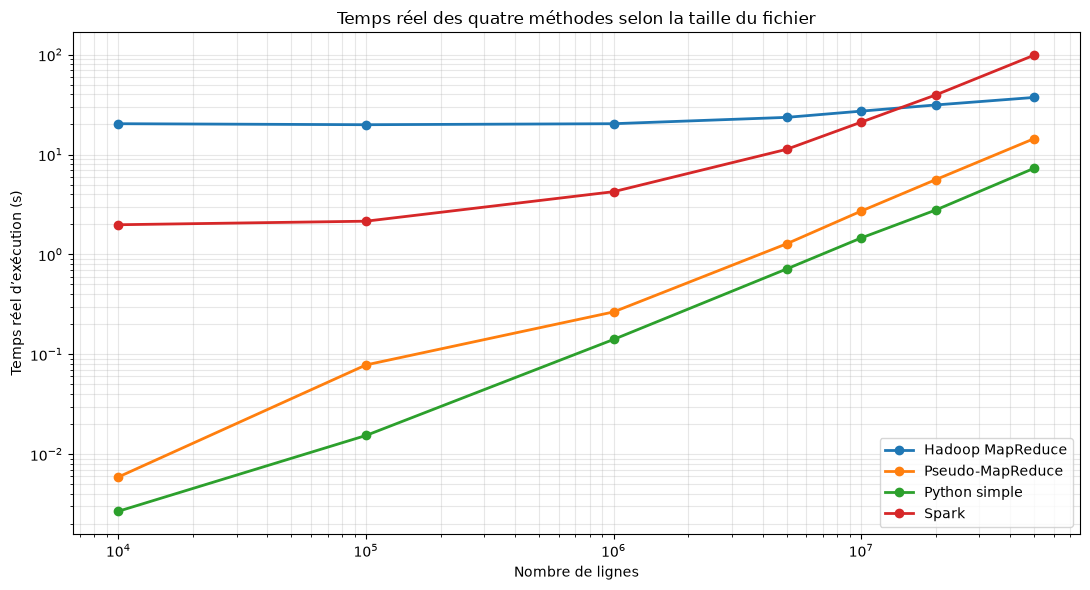

In [11]:
plt.figure(figsize=(11, 6))
for methode, groupe in resultats.groupby('méthode'):
    plt.plot(groupe['lignes'], groupe['temps_s'], marker='o', linewidth=2, label=methode)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Nombre de lignes')
plt.ylabel('Temps réel d’exécution (s)')
plt.title('Temps réel des quatre méthodes selon la taille du fichier')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(DOSSIER / 'benchmark_grandes_tailles.png', dpi=150, bbox_inches='tight')
plt.show()

## Conclusion

Le benchmark est complet : les 28 mesures (7 tailles × 4 méthodes) ont été enregistrées et chaque méthode a produit exactement les comptages attendus. Les temps augmentent globalement avec le nombre de lignes, mais les méthodes distribuées subissent un coût fixe important lié au démarrage, aux transferts et à l'environnement d'exécution.

La version **Python simple** est la plus rapide pour toutes les tailles testées : elle passe de 0,002 s pour 10 000 lignes à 6,937 s pour 50 millions de lignes. Le **pseudo-MapReduce** suit la même évolution, mais reste plus lent (14,035 s à 50 millions de lignes, soit environ 2 fois le temps de Python), en raison de la création et de la fusion des blocs intermédiaires.

**Hadoop MapReduce** est très pénalisé sur les petits fichiers par ses coûts de lancement : il prend environ 20,7 s dès 10 000 lignes. Il devient toutefois plus rapide que Spark à partir de 20 millions de lignes et termine le test de 50 millions de lignes en 35,431 s. **Spark** est plus rapide qu'Hadoop sur les petites tailles grâce à un démarrage moins coûteux (2,007 s pour 10 000 lignes), mais son temps atteint 94,319 s à 50 millions de lignes dans cette configuration locale (`local[2]`).

Ces résultats montrent donc que, pour ce poste et ce traitement simple, le parallélisme Hadoop/Spark ne compense pas les surcoûts d'exécution : Python séquentiel est le meilleur choix en temps brut. Hadoop pourrait devenir pertinent pour des volumes ou un cluster réellement distribués, tandis que l'usage de blocs permet au pseudo-MapReduce de conserver une mémoire intermédiaire bornée plutôt que de charger tout le fichier. Enfin, une seule exécution par configuration ne suffit pas à quantifier la variabilité ; plusieurs répétitions et la médiane seraient nécessaires pour une comparaison plus robuste.
